
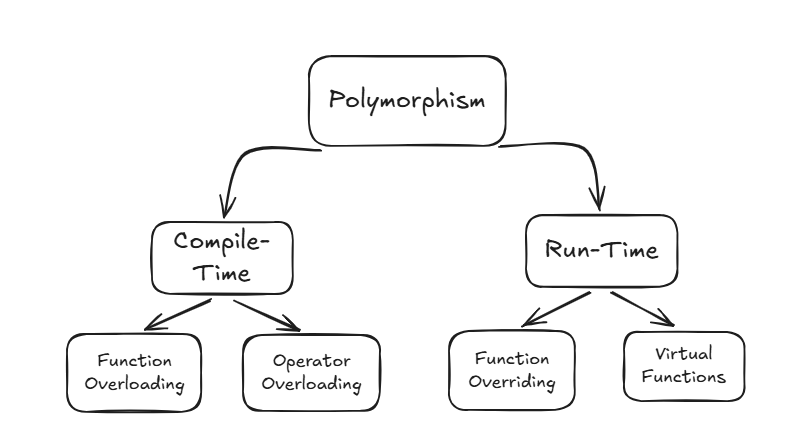

# Polymorphism:

- Polymorphism is one of the core pillars of Object-Oriented Programming (OOP). The word comes from Greek, meaning "many forms."

## Compile- Time:
- Compile-time polymorphism (also called static binding or early binding) occurs when the C++ compiler selects the correct function or operator to execute during compilation, long before the program runs.

### Function overloading:

- Function overloading allows you to have multiple functions with the exact same name in the same scope, as long as their parameter lists (signatures) are different.

### Operator Overloading:

- Operator overloading allows you to redefine how standard C++ operators (like +, -, *, <<) work when applied to custom objects (user-defined types).For example, the + operator naturally adds two integers. By overloading it, we can teach it to add two complex math coordinates together.

In [ ]:
#include <iostream>
using namespace std;

class Complex {
private:
    int real, imag;
public:
    Complex(int r = 0, int i = 0) : real(r), imag(i) {}

    // Overloading the '+' operator
    Complex operator + (Complex const& obj) {
        Complex res;
        res.real = real + obj.real; // Adds real parts
        res.imag = imag + obj.imag; // Adds imaginary parts
        return res;
    }

    void display() {
        cout << real << " + " << imag << "i" << endl;
    }
};

int main() {
    Complex c1(3, 4), c2(2, 5);

    // The '+' operator acts polymorphically on our objects!
    Complex c3 = c1 + c2; 
    
    c3.display(); // Outputs: 5 + 9i
    return 0;
}

## Key Rules of Compile-Time Polymorphism:

- Return Type is Not Enough: You cannot overload a function by changing only its return type. The parameters must change.
- Performance Benefit: Because choices are made at compile time, there is zero runtime overhead. The program runs as fast as if you had written completely separate function names.

## Run-Time:

- Runtime polymorphism (also called dynamic binding or late binding) occurs when the C++ compiler delays selecting the function to execute until the program is actively running.

- Unlike compile-time polymorphism, where decisions are based on data types, runtime polymorphism is determined by the actual object being pointed to at execution time. This allows you to write flexible, extensible code where a single interface can interact with many different underlying object types.


- In C++, runtime polymorphism is achieved using two core ingredients:
    1. Function Overriding (re-defining a base class method inside a derived class).
    2. Virtual Functions (marking the base class function with the virtual keyword).

### Function Overriding:

- Function overriding is a feature in C++ that allows a child class to provide a specific implementation of a method that is already provided by its parent class.

#### Rules:
- Inheritance: There must be a parent-child relationship between the classes.
- Exact Match: The function name, return type, and parameter list (signature) must be identical in both classes.
- virtual Keyword: The base class function must be marked with the virtual keyword to enable dynamic binding.
- override Identifier (Optional but Recommended): You should append override to the child class function. This tells the compiler to check for typos or mismatch errors.


In [ ]:
#include <iostream>
using namespace std;

class Base {
public:
    // Virtual keyword allows this function to be overridden dynamically
    virtual void show() {
        cout << "Inside Base Class show()" << endl;
    }
};

class Derived : public Base {
public:
    // Overriding the base class show() method
    void show() override {
        cout << "Inside Derived Class show() - Specific implementation!" << endl;
    }
};

int main() {
    // Scenario 1: Base pointer pointing to Derived object
    Base* ptr = new Derived();
    
    // Calls the overridden child function due to dynamic binding
    ptr->show(); // Outputs: Inside Derived Class show() - Specific implementation!
    
    // Scenario 2: Accessing the original parent function
    // You can still call the base version using the scope resolution operator (::)
    ptr->Base::show(); // Outputs: Inside Base Class show()

    delete ptr;
    return 0;
}

## base reference bhi runtime polymorphism enable karta hai.

In [ ]:
void makeSound(Animal &a) {
    a.sound();
}

Dog d;

makeSound(d);

## Virtual Destructor